# PathSnap · 02 gaussian nb

Upload train_candidates.csv and student_test_candidates.csv to Colab’s Files panel.

Keep the model's metrics CSV and fitted .joblib file from pathsnap_real/ for notebook 06. Top-1 covers observations with candidate rows and uses the supplied candidate labels.

In [1]:
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
from sklearn.model_selection import GroupKFold, cross_val_score
from sklearn.metrics import f1_score, log_loss
from time import perf_counter

FEATURES = ['dist_m', 'dist_min_m', 'dist_rel_m', 'rank_dist', 'n_cands', 'proj_frac', 'arc_len_m', 'dist_end_m', 'head_diff_deg', 'head_cos', 'speed_mps', 'moving', 'dt_prev_s', 'dist_prev_pt_m', 'dist_next_pt_m', 'has_reverse', 'deg_from', 'deg_to']
KEYS = ["trip_id", "observation_index", "arc_id"]
ROOT = Path("pathsnap_real")
ROOT.mkdir(exist_ok=True)

def load_candidates(filename):
    if not Path(filename).exists():
        raise FileNotFoundError(f"Upload {filename} to the Colab Files panel.")
    frame = pd.read_csv(filename, dtype={"trip_id": str})
    missing = set(KEYS + FEATURES + ["label"]) - set(frame.columns)
    if missing:
        raise ValueError(f"{filename} is missing columns: {sorted(missing)}")
    assert not frame[KEYS].isna().any().any(), f"Missing IDs in {filename}"
    assert not frame.duplicated(KEYS).any(), f"Duplicate candidate IDs in {filename}"
    assert frame["label"].isin([0, 1]).all(), f"Bad labels in {filename}"
    return frame

train = load_candidates("train_candidates.csv")
test_path = Path("student_test_candidates.csv")
if not test_path.exists():
    test_path = Path("student_test_candidates(1).csv")
test = load_candidates(test_path)

assert set(train.trip_id).isdisjoint(test.trip_id)
assert train.trip_id.nunique() >= 2
X, y = train[FEATURES], train.label
folds = list(GroupKFold(min(5, train.trip_id.nunique())).split(X, y, train.trip_id))
assert all(y.iloc[i].nunique() == 2 for i, _ in folds)

def evaluate(model):
    start = perf_counter()
    probabilities = model.predict_proba(test[FEATURES])
    seconds = perf_counter() - start
    scored = test[KEYS + ["label"]].copy()
    scored["p_match"] = probabilities[:, list(model.classes_).index(1)]
    top = scored.sort_values("p_match", ascending=False, kind="stable").drop_duplicates(KEYS[:2])
    return scored, {
        "student_top1_with_candidates": top.label.mean(),
        "student_candidate_macro_f1": f1_score(test.label, model.classes_[probabilities.argmax(axis=1)], average="macro"),
        "log_loss": log_loss(test.label, probabilities, labels=model.classes_),
        "inference_seconds": seconds,
    }


In [2]:
from sklearn.naive_bayes import GaussianNB
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

NAME = "02_gaussian_nb"
model = make_pipeline(SimpleImputer(strategy="median"), GaussianNB())
cv = cross_val_score(model, X, y, cv=folds, scoring="f1_macro", error_score="raise")
model.fit(X, y)
_, metrics = evaluate(model)
summary = pd.DataFrame([{"model": NAME, "cv_macro_f1": cv.mean(), **metrics}])
summary.to_csv(ROOT / f"{NAME}.csv", index=False)
joblib.dump(model, ROOT / f"{NAME}.joblib")
print(ROOT / f"{NAME}.csv", ROOT / f"{NAME}.joblib")
display(summary)


pathsnap_real/02_gaussian_nb.csv pathsnap_real/02_gaussian_nb.joblib


,model,cv_macro_f1,student_top1_with_candidates,student_candidate_macro_f1,log_loss,inference_seconds
0,02_gaussian_nb,0.825294,0.825418,0.817809,0.542196,0.089673


### Gaussian Naive Bayes improvement experiments

We run two experimental variants to see if we can improve on the baseline Gaussian NB performance:
1. **Heading only once**: Remove `head_cos` to avoid redundant angular information.
2. **Variance smoothing**: Tune `var_smoothing` parameter using the grouped CV folds.

In [3]:
import numpy as np
import pandas as pd
import joblib
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import cross_val_score

# --- Variant 1: Heading only once (remove 'head_cos') ---
features_no_head_cos = [f for f in FEATURES if f != 'head_cos']
X_no_head_cos = train[features_no_head_cos]

model_v1 = make_pipeline(SimpleImputer(strategy="median"), GaussianNB())
cv_v1 = cross_val_score(model_v1, X_no_head_cos, y, cv=folds, scoring="f1_macro", error_score="raise")
model_v1.fit(X_no_head_cos, y)

# Evaluate Variant 1 on student-test data
start_v1 = perf_counter()
probabilities_v1 = model_v1.predict_proba(test[features_no_head_cos])
seconds_v1 = perf_counter() - start_v1

scored_v1 = test[KEYS + ["label"]].copy()
scored_v1["p_match"] = probabilities_v1[:, list(model_v1.classes_).index(1)]
top_v1 = scored_v1.sort_values("p_match", ascending=False, kind="stable").drop_duplicates(KEYS[:2])

metrics_v1 = {
    "model": "02_gaussian_nb_heading_once",
    "cv_macro_f1": cv_v1.mean(),
    "student_top1_with_candidates": top_v1.label.mean(),
    "student_candidate_macro_f1": f1_score(test.label, model_v1.classes_[probabilities_v1.argmax(axis=1)], average="macro"),
    "log_loss": log_loss(test.label, probabilities_v1, labels=model_v1.classes_),
    "inference_seconds": seconds_v1
}

# --- Variant 2: Variance smoothing grid search ---
var_smoothing_candidates = [1e-9, 1e-8, 1e-7, 1e-6, 1e-5, 1e-4, 1e-3, 1e-2, 1e-1]
best_cv_f1 = -1
best_var_smoothing = None

for vs in var_smoothing_candidates:
    temp_model = make_pipeline(SimpleImputer(strategy="median"), GaussianNB(var_smoothing=vs))
    scores = cross_val_score(temp_model, X, y, cv=folds, scoring="f1_macro", error_score="raise")
    mean_score = scores.mean()
    if mean_score > best_cv_f1:
        best_cv_f1 = mean_score
        best_var_smoothing = vs

# Fit and evaluate best variance smoothing model on full dataset
model_v2 = make_pipeline(SimpleImputer(strategy="median"), GaussianNB(var_smoothing=best_var_smoothing))
model_v2.fit(X, y)

start_v2 = perf_counter()
probabilities_v2 = model_v2.predict_proba(test[FEATURES])
seconds_v2 = perf_counter() - start_v2

scored_v2 = test[KEYS + ["label"]].copy()
scored_v2["p_match"] = probabilities_v2[:, list(model_v2.classes_).index(1)]
top_v2 = scored_v2.sort_values("p_match", ascending=False, kind="stable").drop_duplicates(KEYS[:2])

metrics_v2 = {
    "model": f"02_gaussian_nb_var_smoothing_{best_var_smoothing}",
    "cv_macro_f1": best_cv_f1,
    "student_top1_with_candidates": top_v2.label.mean(),
    "student_candidate_macro_f1": f1_score(test.label, model_v2.classes_[probabilities_v2.argmax(axis=1)], average="macro"),
    "log_loss": log_loss(test.label, probabilities_v2, labels=model_v2.classes_),
    "inference_seconds": seconds_v2
}

# --- Combine results into a single table ---
baseline_row = {
    "model": "02_gaussian_nb_baseline",
    "cv_macro_f1": summary.loc[0, "cv_macro_f1"],
    "student_top1_with_candidates": summary.loc[0, "student_top1_with_candidates"],
    "student_candidate_macro_f1": summary.loc[0, "student_candidate_macro_f1"],
    "log_loss": summary.loc[0, "log_loss"],
    "inference_seconds": summary.loc[0, "inference_seconds"]
}

experiments_df = pd.DataFrame([baseline_row, metrics_v1, metrics_v2])
experiments_df.to_csv(ROOT / "02_gaussian_nb_experiments.csv", index=False)
display(experiments_df)

,model,cv_macro_f1,student_top1_with_candidates,student_candidate_macro_f1,log_loss,inference_seconds
0,02_gaussian_nb_baseline,0.825294,0.825418,0.817809,0.542196,0.089673
1,02_gaussian_nb_heading_once,0.777961,0.818006,0.782318,0.592462,0.092189
2,02_gaussian_nb_var_smoothing_0.001,0.839618,0.796868,0.840374,0.371144,0.084597


Accuracy:          0.9279
Precision (Match): 0.5354
Recall (Match):    0.9174
F1 (Match):        0.6762
Macro F1:          0.8178
ROC AUC:           0.9753


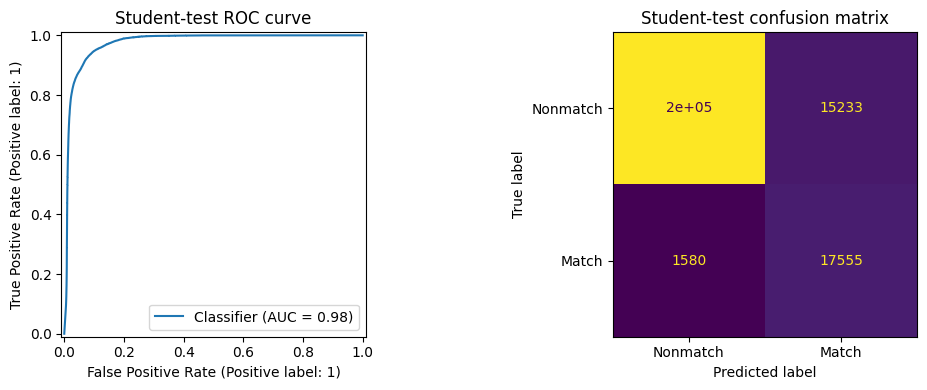

In [6]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, RocCurveDisplay, ConfusionMatrixDisplay,
)
import matplotlib.pyplot as plt

X_test = test[FEATURES]
y_true = test["label"]
y_pred = model.predict(X_test)
match_col = list(model.classes_).index(1)
p_match = model.predict_proba(X_test)[:, match_col]

print(f"Accuracy:          {accuracy_score(y_true, y_pred):.4f}")
print(f"Precision (Match): {precision_score(y_true, y_pred, zero_division=0):.4f}")
print(f"Recall (Match):    {recall_score(y_true, y_pred, zero_division=0):.4f}")
print(f"F1 (Match):        {f1_score(y_true, y_pred, zero_division=0):.4f}")
print(f"Macro F1:          {f1_score(y_true, y_pred, average='macro'):.4f}")
print(f"ROC AUC:           {roc_auc_score(y_true, p_match):.4f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
RocCurveDisplay.from_predictions(y_true, p_match, ax=axes[0])
axes[0].set_title("Student-test ROC curve")

ConfusionMatrixDisplay.from_predictions(
    y_true, y_pred,
    labels=[0, 1],
    display_labels=["Nonmatch", "Match"],
    ax=axes[1],
    colorbar=False,
)
axes[1].set_title("Student-test confusion matrix")
plt.tight_layout()
plt.show()